![Ironhack logo](https://user-images.githubusercontent.com/23629340/40541063-a07a0a8a-601a-11e8-91b5-2f13e4e6b441.png)

# 02 | Pipelines and Models

*Project 2 — Machine Learning: From Data to Predictions*

**Student:** Gabriel Gomes

**Dataset:** WikiArt

---
## Setup

In [18]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader

import sys
sys.path.append("..")         
import time
from copy import deepcopy

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score, ConfusionMatrixDisplay

%load_ext autoreload
%autoreload 2
from src.functions import *
from src.nn_functions import *

pd.set_option("display.max_columns", 100)

device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


---
## 1. Load and split

In [2]:
df = build_dataframe(RAW)

In [3]:
train = pd.read_csv( SPLIT / "split_train.csv")
val = pd.read_csv(SPLIT / "split_val.csv")

---
## 2. Architecture of the CNN


`ArtistCNN` is a small convolutional network trained from scratch to classify a painting into one of six painters. It takes a batch of RGB images of 224×224 pixels with raw values from 0 to 255 and returns six logits, one per painter. It has about 94,000 trainable parameters, a small fraction of a pretrained backbone such as MobileNetV2 (about 2.2 million parameters in its feature extractor). That makes it a useful baseline for judging how much transfer learning adds.

**1. Preprocessing and augmentation** (`preprocess`)

The preprocessing is part of the model, so the same code path is used in training and in inference. It has four steps:

| Layer | Role |
|---|---|
| `RandomFlip` | Mirrors each image horizontally with probability 0.5. A mirrored painting keeps its style, so this adds variety without changing the label. |
| `RandomRotation(0.05)` | Rotates each image by a random angle of up to ±18°. The range is kept small because strong rotations alter the composition cues of a painting. |
| `RandomZoom(0.1)` | Zooms in or out by up to 10%, which helps the model cope with different scales of brushwork and subject. |
| `Rescaling(1/255)` | Converts pixel values from 0–255 to 0–1, which keeps the inputs in a range that is easier to optimize. |

The three augmentation layers act only in training mode and are skipped in evaluation mode, so validation and test scores are not affected by randomness. Augmentation acts as a regularizer, since the network rarely sees exactly the same image twice.

**2. Feature extractor** (`features`)

Three `conv_block` stages extract increasingly abstract visual patterns. Each block contains the same three operations:

- **3×3 convolution (with padding)**: learns a set of filters that respond to local patterns, and keeps the image size unchanged.
- **ReLU**: a non-linearity that lets the network model more than linear combinations of pixels.
- **2×2 max pooling**: halves the width and height, keeping the strongest response in each neighborhood. This makes the features less sensitive to small shifts and reduces computation.

| Block | Channels | Output size (for a 224×224 input) | What it tends to learn |
|---|---|---|---|
| 1 | 3 → 32 | 112×112 | Edges, color contrasts, simple strokes |
| 2 | 32 → 64 | 56×56 | Textures and stroke patterns |
| 3 | 64 → 128 | 28×28 | Combinations of textures and local shapes |

Channels double at each stage while the spatial size halves, a common design that trades spatial resolution for richer features. Since brushwork is a key signal for telling painters apart, the convolutional stages are where most of the style information is captured.

**3. Global pooling** (`pool`)

`AdaptiveAvgPool2d(1)` averages each of the 128 feature maps into a single value, producing a 128-dimensional vector per image. This has three benefits:

- It removes the need for a large fully connected layer, so there are far fewer parameters and less overfitting.
- It makes the model independent of the input resolution.
- It summarizes how strongly each learned pattern appears anywhere in the painting, which suits style recognition, where texture matters more than exact position.

**4. Classification head** (`head`)
   
- `Flatten`: reshapes the pooled output into a plain vector.
- `Dropout(0.4)`: during training, randomly sets 40% of the 128 features to zero, so the classifier cannot depend on any single feature. It is off in evaluation mode.
- `Linear(128 → 6)`: maps the features to one score (logit) per painter.

**Output and inference**

The network returns **logits** and not probabilities, because `CrossEntropyLoss` applies the softmax internally, which is numerically more stable. For inference and the demo, `predict_proba` switches the model to evaluation mode (disabling augmentation and dropout), disables gradient computation, and applies a softmax to give probabilities that sum to 1. 

**Summary**

| Stage | Layer | Output shape | Parameters |
|---|---|---|---|
| Input | Raw RGB image | 3×224×224 | 0 |
| `preprocess` | RandomFlip, RandomRotation, RandomZoom, Rescaling | 3×224×224 | 0 |
| `features` (block 1) | Conv2d 3→32, ReLU, MaxPool | 32×112×112 | 896 |
| `features` (block 2) | Conv2d 32→64, ReLU, MaxPool | 64×56×56 | 18,496 |
| `features` (block 3) | Conv2d 64→128, ReLU, MaxPool | 128×28×28 | 73,856 |
| `pool` | AdaptiveAvgPool2d(1) | 128×1×1 | 0 |
| `head` | Flatten, Dropout(0.4), Linear 128→6 | 6 | 774 |
| **Total** | | | **94,022** |

**Design rationale and limitations**

The network is deliberately small, with three blocks and no batch normalization, to keep training fast on a laptop GPU and to serve as a clear baseline. Its limits are that the filters are learned from only a few thousand images, so it cannot match the general-purpose features of a model pretrained on ImageNet, and the 224×224 input compresses fine brushwork detail. These are the reasons for comparing it with the transfer-learning model in the next step.

**PyTorch over Keras**

I chose PyTorch over TensorFlow/Keras mainly because it has become the dominant framework in recent years, which means more up-to-date tutorials, pretrained models (such as the torchvision MobileNetV2 used here), and community support. It also fit my setup better: PyTorch supports GPU training on Apple Silicon through the MPS backend with a standard install, whereas TensorFlow needed the more fragile tensorflow-metal plugin and did not work with my newer Python version. Its explicit training loop also gave me finer control over details such as early stopping, class-weighted loss, and keeping the frozen backbone in evaluation mode.

**Loss and optimizer**

The model is trained with a class-weighted cross-entropy loss (`nn.CrossEntropyLoss`), the standard loss for multi-class classification. It takes the network’s raw outputs, applies a softmax internally, and penalizes low probability on the true painter. Each class is weighted inversely to its frequency in the training set, so errors on the rare painters (Manet, Morisot) cost more than errors on Van Gogh, which counters the class imbalance without discarding data. The weights are computed from the training set only.

The weights are updated with the AdamW optimizer, which adapts the step size for each parameter, using a learning rate of 0.001 and a weight decay of 0.0001. The weight decay is a small regularization penalty that shrinks the weights toward zero at each step and helps limit overfitting. Both the loss and the optimizer are used in every training step.

In [4]:
classes, class_to_idx = get_class_mapping(df)

train_dl = DataLoader(PaintingDataset(train, class_to_idx), batch_size=8, shuffle=True, num_workers=0)
val_dl = DataLoader(PaintingDataset(val, class_to_idx), batch_size=8, num_workers=0)

# class weights to handle the imbalance (computed from the training set only)
counts = train["artist"].map(class_to_idx).value_counts().sort_index()
weights = torch.tensor(len(train) / (len(classes) * counts.values), dtype=torch.float32)

cnn = ArtistCNN(num_classes=len(classes)).to(device)
criterion = nn.CrossEntropyLoss(weight=weights.to(device))
opt_cnn = torch.optim.AdamW(cnn.parameters(), lr=1e-3, weight_decay=1e-4)

---
## 3. Training the CNN from scratch

The CNN is trained by the `fit` function, which loops over epochs, up to a maximum of 50. In each epoch, the model first runs through the training set (`train_dl`), computing the class-weighted loss (`criterion`) and updating its weights with the AdamW optimizer (`opt_cnn`). It then runs through the validation set (`val_dl`) without updating any weights, to measure the validation loss and macro-F1. During training, the augmentation layers and dropout are active; during validation they are switched off, so the validation scores are not affected by randomness. All computation runs on the chosen device.

Training is controlled by early stopping on the validation loss. If the validation loss does not improve for 5 consecutive epochs (`patience=5`), training stops, so the model is not trained longer than useful and overfitting is limited. The 50-epoch limit is only an upper bound, and in practice early stopping decides the real number of epochs. The function keeps a copy of the weights from the epoch with the lowest validation loss and restores them at the end, so the returned model is the best one, not the last one.

In [5]:
start = time.perf_counter()
history_cnn, best_epoch_cnn = fit(cnn, opt_cnn, train_dl, val_dl, criterion, device, max_epochs=50, patience=5)
train_time_cnn = time.perf_counter() - start

print(f"Training time: {train_time_cnn/60:.1f} min")

epoch  1 | train loss 1.681 F1 0.239 | val loss 1.446 F1 0.319
epoch  2 | train loss 1.587 F1 0.319 | val loss 1.395 F1 0.344
epoch  3 | train loss 1.578 F1 0.337 | val loss 1.397 F1 0.309
epoch  4 | train loss 1.540 F1 0.348 | val loss 1.275 F1 0.364
epoch  5 | train loss 1.501 F1 0.378 | val loss 1.323 F1 0.391
epoch  6 | train loss 1.475 F1 0.405 | val loss 1.319 F1 0.381
epoch  7 | train loss 1.455 F1 0.397 | val loss 1.404 F1 0.399
epoch  8 | train loss 1.437 F1 0.414 | val loss 1.254 F1 0.446
epoch  9 | train loss 1.433 F1 0.418 | val loss 1.409 F1 0.404
epoch 10 | train loss 1.411 F1 0.420 | val loss 1.306 F1 0.432
epoch 11 | train loss 1.410 F1 0.428 | val loss 1.357 F1 0.412
epoch 12 | train loss 1.400 F1 0.434 | val loss 1.298 F1 0.465
epoch 13 | train loss 1.382 F1 0.445 | val loss 1.300 F1 0.418
Early stopping at epoch 13. Best epoch: 8
Training time: 10.2 min


After being trained, the model and its metadata are saved as a PyTorch file.

In [ ]:
print(f"Best epoch: {best_epoch_cnn} | "
      f"best val loss: {min(history_cnn['val_loss']):.3f}")

# ---------- save weights together with metadata ----------
torch.save({
    "model_state": cnn.state_dict(),
    "best_epoch": best_epoch_cnn,
    "best_val_loss": min(history_cnn["val_loss"]),
    "train_time": train_time_cnn,
    "history": history_cnn,
    "classes": classes,
    "img_size": IMG_SIZE,
    "model_class": "CNN",
}, MODELS / "model_cnn.pt")

Loading the cell below prevents having to train the model again. 

In [30]:
model_cnn = torch.load(MODELS / "model_cnn.pt", map_location=device)

cnn_loaded = ArtistCNN(num_classes=len(model_cnn["classes"])).to(device)
cnn_loaded.load_state_dict(model_cnn["model_state"])
cnn_loaded.eval()

ArtistCNN(
  (preprocess): Sequential(
    (0): RandomFlip()
    (1): RandomRotation()
    (2): RandomZoom()
    (3): Rescaling()
  )
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU(inplace=True)
      (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU(inplace=True)
      (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (2): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU(inplace=True)
      (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
  )
  (pool): AdaptiveAvgPool2d(output_size=1)
  (head): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Dropout(p=0.4, inplace=False)
    (2): Linear(in_features=12

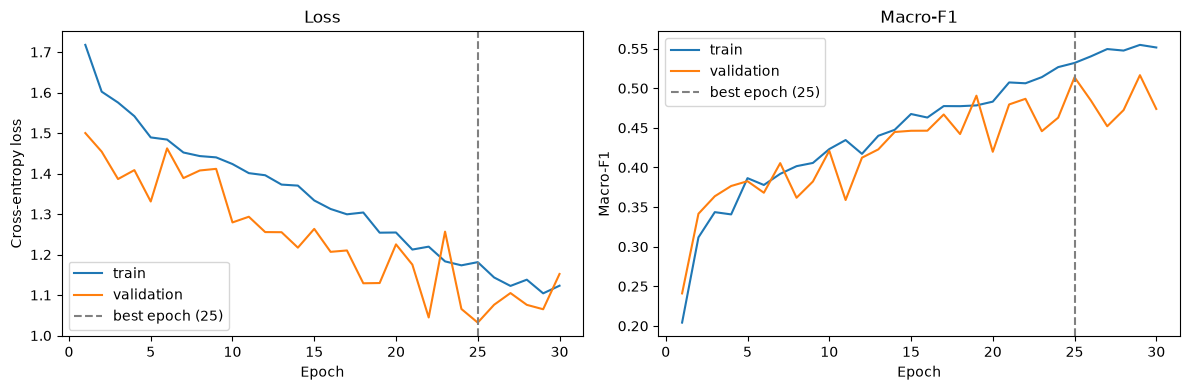

In [31]:
history_cnn = model_cnn["history"]
best_epoch_cnn = model_cnn["best_epoch"]

epochs = range(1, len(history_cnn["train_loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epochs, history_cnn["train_loss"], label="train")
axes[0].plot(epochs, history_cnn["val_loss"], label="validation")
axes[0].axvline(best_epoch_cnn, color="gray", linestyle="--", label=f"best epoch ({best_epoch_cnn})")
axes[0].set(title="Loss", xlabel="Epoch", ylabel="Cross-entropy loss")
axes[0].legend()

axes[1].plot(epochs, history_cnn["train_f1"], label="train")
axes[1].plot(epochs, history_cnn["val_f1"], label="validation")
axes[1].axvline(best_epoch_cnn, color="gray", linestyle="--", label=f"best epoch ({best_epoch_cnn})")
axes[1].set(title="Macro-F1", xlabel="Epoch", ylabel="Macro-F1")
axes[1].legend()

plt.tight_layout()
plt.show()

### Evaluation of the training curves

**Overview**. The model was trained for 30 epochs. Early stopping (patience 5) ended training after the best validation loss was reached at epoch 25, at about 1.03. At that epoch the validation macro-F1 is about 0.51, and the restored weights are those of epoch 25.

**1. The model learns real signal.** Both metrics improve substantially over the first epochs. A validation macro-F1 of about 0.5 is far above the 0.084 of the majority-class baseline, so the network has learned to distinguish painters from style information and not from the class distribution. It is, however, a modest score in absolute terms, and the model clearly leaves room for improvement.

**2. There is no clear overfitting.** Overfitting would show as training loss continuing to fall while validation loss rises and the two curves separate. Here the training loss stays above the validation loss for almost the whole run, and the training F1 is only slightly higher than the validation F1. The training metrics are computed with augmentation and dropout active, and averaged while the weights change during the epoch, which makes them look worse than the validation metrics, which are computed in evaluation mode. The model therefore seems to be underfitting or still undertrained: the training curves had not flattened when training stopped.

**3. The validation curves are noisy.** The validation loss and F1 jump from epoch to epoch (for example, the loss spikes at epochs 6 and 23 and drops sharply at epoch 22, and the F1 oscillates by about 0.05 between neighboring epochs). One likely reason is that the smallest classes (Manet and Morisot) have only a few dozen validation images, so a handful of predictions changing class moves the macro-F1 noticeably.

**4. Early stopping behaved as designed but was driven by noise.** The best validation loss at epoch 25 is a sharp dip, and the five following epochs failed to beat it, ending training. Because the training curves were still improving, the stop reflects the noisy validation signal more than the model having converged.

**5. Conclusion.** ArtistCNN works as a baseline, with a validation macro-F1 of about 0.5, and it is limited by its small capacity and short training, not by overfitting.

              precision    recall  f1-score   support

    Cézanne       0.61      0.20      0.31        83
       Manet       0.46      0.33      0.39        33
       Monet       0.67      0.74      0.70       191
     Morisot       0.23      0.46      0.30        35
      Renoir       0.88      0.50      0.64       198
    Van Gogh       0.64      0.88      0.74       272

    accuracy                           0.64       812
   macro avg       0.58      0.52      0.51       812
weighted avg       0.68      0.64      0.63       812



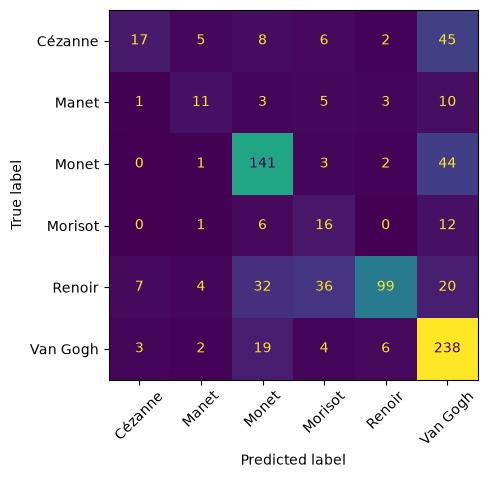

In [32]:
cnn_loaded.eval()
y_true, y_pred = [], []
with torch.no_grad():
    for x, y in val_dl:
        y_pred += cnn_loaded(x.to(device)).argmax(1).cpu().tolist()
        y_true += y.tolist()

print(classification_report(y_true, y_pred, target_names=classes))
ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred), display_labels=classes).plot(xticks_rotation=45, colorbar=False)

### Evaluation of the classification report and confusion matrix

The 812 evaluated images (about 14% of the dataset) are classified with an **accuracy of 0.64** and a **macro-F1 of 0.51**. The majority-class baseline scored 0.335 accuracy and 0.084 macro-F1, so ArtistCNN nearly doubles the accuracy and multiplies the macro-F1 by about six. 

**Per-class results**

| Painter | Precision | Recall | F1 | Support | Main pattern |
|---|---:|---:|---:|---:|---|
| Van Gogh | 0.64 | 0.88 | 0.74 | 272 | Best recall, but absorbs many wrong predictions |
| Monet | 0.67 | 0.74 | 0.70 | 191 | Solid, balanced |
| Renoir | 0.88 | 0.50 | 0.64 | 198 | Very precise, but misses half of his paintings |
| Manet | 0.46 | 0.33 | 0.39 | 33 | Weak and noisy (small class) |
| Cézanne | 0.61 | 0.20 | 0.31 | 83 | Rarely predicted, 80% of his paintings missed |
| Morisot | 0.23 | 0.46 | 0.30 | 35 | Over-predicted, so many false alarms |

The gap between accuracy (0.64) and macro-F1 (0.51) shows that the large classes (Van Gogh, Monet, Renoir) carry the accuracy while the small ones (Cézanne, Manet, Morisot) are much weaker, which is the reason macro-F1 was chosen as the main metric.

**Main patterns in the confusion matrix**

**1. Van Gogh acts as an attractor.** His column holds 369 predictions, of which 131 are wrong. The largest sources are Cézanne (45 of 83 paintings, 54% of the class), Monet (44, 23%), Renoir (20), and Morisot (12). The model seems to treat bold, visible brushwork and saturated color as “Van Gogh”, which also explains why the recall for him is high (0.88) while the precision is lower (0.64). The confusion with Cézanne is plausible, since both are Post-Impressionists who kept strong color and visible strokes. It also contradicts my earlier expectation that Cézanne would be an easy class, because his structured, geometric strokes are not being picked up by this small network.

**2. Renoir is confused with his stylistic neighbors.** Of his 198 paintings, 36 are predicted as Morisot and 32 as Monet. This matches the expected overlap: Renoir shares Monet’s light and loose brushwork, and Morisot’s soft, feathery figure paintings. His precision is high (0.88), so when the model says Renoir it is almost always right, but it says so too rarely.

**3. Morisot is over-predicted.** The model predicts Morisot 70 times, but only 16 are correct (precision 0.23), and 36 of the false alarms are Renoir paintings. This is probably an effect of the class-weighted loss: Morisot has one of the largest weights, which raises her recall (0.46) at the cost of precision. It is the classic precision-recall trade-off of reweighting.

**4. Cézanne is under-predicted.** The model predicts Cézanne only 28 times against 83 true paintings. The class weights did not compensate for this, because the features of this small network do not separate his style from Van Gogh’s.

**5. Monet is the most reliable Impressionist.** He has the cleanest diagonal (141 of 191). His errors go mainly to Van Gogh (44), and a further 32 Renoir paintings are labeled Monet, consistent with the “reference point” role of his style.

**6. Manet is hard to evaluate.** His errors are spread across all classes, which fits a painter whose style ranges from flat, dark early work to loose outdoor scenes. With only 33 test images, each misclassification moves his recall by 3 points, so his scores are very uncertain.

**Conclusion and next steps**

`ArtistCNN` learns real stylistic signal but leans on coarse cues (color and stroke boldness), which causes the Van Gogh attraction and the weakness on Cézanne. The next steps will then be to implement transfer learning with the pretrained MobileNetV2, which should give more discriminating texture features, especially for the small classes.

---
## 4. Training a transfer-learning network

`TransferNet` is a transfer-learning classifier. It reuses the convolutional feature extractor of **MobileNetV2 pretrained on ImageNet** and adds a new, small classification head for the six painters. Instead of learning visual features from a few thousand paintings, as `ArtistCNN` does, it starts from general features (edges, textures, color patterns, shapes) learned from more than a million natural images, and trains only the final layer that maps them to painters. It takes a batch of RGB images (224×224, raw values 0 to 255) and returns six logits. Of its roughly 2.23 million parameters, only 7,686 are trainable (the head), and the other 2.22 million belong to the frozen backbone.

**1. Input scaling, augmentation and normalization**

The preprocessing is part of the model, so training and inference follow the same code path.

| Step | Operation | Role |
|---|---|---|
| Scaling | `x.float() / 255` | Converts pixel values from 0–255 to 0–1 |
| `augment` | `RandomFlip`, `RandomRotation(0.05)`, `RandomZoom(0.1)` | Random horizontal flips, rotations of up to ±18° and zooms of up to 10%, active in training mode only |
| Normalization | `(x - mean) / std` | Standardizes each RGB channel with the ImageNet statistics (mean 0.485, 0.456, 0.406; std 0.229, 0.224, 0.225) that the pretrained backbone expects |

The augmentation is identical to that of `ArtistCNN`, so any difference in results between the two models comes from the architecture and the pretrained weights, not from the preprocessing. The mean and standard deviation are stored as **buffers**: they move with the model to the GPU and are saved in its state dictionary, but they are not trained.

**2. Frozen feature extractor** (`base`)

`base` is the `features` part of `torchvision`’s MobileNetV2, which corresponds to loading the network without its original 1000-class classifier (`include_top=False`). It consists of three kinds of components:

- **A stem:** a 3×3 convolution with stride 2 that produces 32 channels.
- **Seventeen inverted residual blocks.** Each one expands the channels with a 1×1 convolution, filters them with a lightweight 3×3 *depthwise* convolution (one filter per channel), and compresses them again with a linear 1×1 convolution. When the input and output shapes match, a skip connection adds the input to the output. Depthwise convolutions are what keep the network small and fast, with about 2.2 million parameters.
- **A final 1×1 convolution** that expands the representation to 1280 channels.

For a 224×224 input, the backbone reduces the spatial size by a factor of 32 and returns **1280 feature maps of 7×7**. Early layers respond to edges and color contrasts, middle layers to textures and stroke patterns, and deeper layers to more complex combinations, which is what makes them useful for recognizing painting styles.

All backbone parameters have `requires_grad = False`, so the optimizer never changes them. The overridden `train()` method also keeps `base` in **evaluation mode** during training. This is needed because the backbone contains BatchNorm layers, which would otherwise update their running statistics on the painting images, partly undoing the freezing and making the pretrained features drift.

**3. Global pooling and classification head**
   
| Layer | Operation | Output |
|---|---|---|
| `pool` | `AdaptiveAvgPool2d(1)` | Averages each of the 1280 feature maps into one value, giving a 1280-dimensional descriptor of the whole painting |
| `Flatten` | Reshape | Vector of length 1280 |
| `Dropout(0.3)` | Randomly zeroes 30% of the features during training | Regularization; off in evaluation mode |
| `Linear(1280 → 6)` | Fully connected layer | One logit per painter (7,686 parameters) |

Global average pooling summarizes how strongly each learned pattern appears anywhere in the painting, which suits style recognition, where texture matters more than position. The output is **logits**, because the class-weighted `CrossEntropyLoss` applies the softmax internally. For inference, `predict_proba` switches to evaluation mode (disabling augmentation and dropout), disables gradients and returns softmax probabilities.

**4. Summary of the network**

| Stage | Output shape (224×224 input) | Parameters | Trainable |
|---|---|---|---|
| Input (raw RGB) | 3×224×224 | 0 | – |
| Scaling, `augment`, normalization | 3×224×224 | 0 | – |
| `base` (MobileNetV2 features) | 1280×7×7 | 2,223,872 | No (frozen) |
| `pool` | 1280×1×1 | 0 | – |
| `head` (Flatten, Dropout, Linear) | 6 | 7,686 | Yes |
| **Total** | | **2,231,558** | **7,686** |

**5. Comparison with `ArtistCNN`**

| Aspect | `ArtistCNN` | `TransferNet` |
|---|---|---|
| Feature extractor | 3 convolutional blocks, learned from scratch | MobileNetV2 pretrained on ImageNet |
| Total parameters | about 94,000 | about 2.23 million |
| Trainable parameters | about 94,000 | 7,686 (head only) |
| Output of the extractor | 128 channels | 1280 channels |
| Normalization | Rescaling to 0–1 | Rescaling plus ImageNet mean/std |
| Augmentation and dropout | Flip, rotation, zoom; dropout 0.4 | Same augmentation; dropout 0.3 |

Even though `TransferNet` has about 24 times more parameters, it is much cheaper to train: only 7,686 weights are updated, and no gradients flow through the backbone.

**6. Design rationale and limitations**
   
- **Why transfer learning:** with a few thousand paintings, and only a few dozen for Manet and Morisot, a network trained from scratch has limited material to learn good features from. Pretrained features offer a stronger starting point, and in this project they are the main candidate to improve on the weak classes (Cézanne, Manet, Morisot) of `ArtistCNN`.
- **Why a frozen backbone first:** training only the head is fast, stable and hard to overfit. The backbone can later be partly unfrozen (the last four blocks of `base`, with their BatchNorm layers kept frozen) and trained at a learning rate of about 1e-5, which adapts the high-level features to painting style.
- **Limitations:** ImageNet features were learned on photographs, so they may not capture brushwork as well as they capture objects. The 224×224 input also compresses fine texture detail, which may matter for painters whose styles differ mostly in brushstrokes.

In [10]:
tl_model = TransferNet(num_classes=len(classes)).to(device)
trainable = sum(p.numel() for p in tl_model.parameters() if p.requires_grad)
total = sum(p.numel() for p in tl_model.parameters())
print(f"trainable params: {trainable:,} of {total:,}")

trainable params: 7,686 of 2,231,558


In [ ]:
opt_tl = torch.optim.AdamW(
    [p for p in tl_model.parameters() if p.requires_grad],   # only the new head
    lr=1e-3, weight_decay=1e-4,
)

start = time.perf_counter()
history_tl, best_epoch_tl = fit(tl_model, opt_tl, train_dl, val_dl, criterion, device, max_epochs=50, patience=5)
train_time_tl = time.perf_counter() - start
print(f"Training time: {train_time_tl/60:.1f} min")

torch.save({
    "model_state": tl_model.state_dict(),
    "best_epoch": best_epoch_tl,
    "best_val_loss": min(history_tl["val_loss"]),
    "train_time": train_time_tl,
    "history": history_tl,
    "classes": classes,
    "img_size": IMG_SIZE,
    "model_class": "MobileNetV2",
}, MODELS / "model_mobilenet.pt")

In [33]:
model_tl = torch.load(MODELS / "model_mobilenet.pt", map_location=device)
    
tl_loaded = TransferNet(num_classes=len(model_tl["classes"])).to(device)
tl_loaded.load_state_dict(model_tl["model_state"])
tl_loaded.eval()

TransferNet(
  (augment): Sequential(
    (0): RandomFlip()
    (1): RandomRotation()
    (2): RandomZoom()
  )
  (base): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU6(inplace=True)
    )
    (1): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
          (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
          (2): ReLU6(inplace=True)
        )
        (1): Conv2d(32, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      )
    )
    (2): InvertedResidual(
      (conv): Sequential(
        (0): Conv2d

### Evaluation of the TransferNet training curves

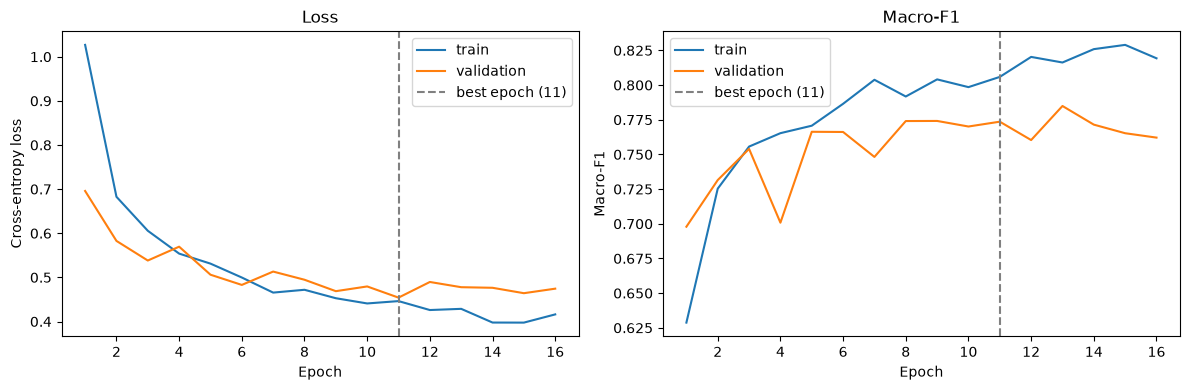

In [34]:
history_tl = model_tl["history"]
best_epoch_tl = model_tl["best_epoch"]

epochs = range(1, len(history_tl["train_loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epochs, history_tl["train_loss"], label="train")
axes[0].plot(epochs, history_tl["val_loss"], label="validation")
axes[0].axvline(best_epoch_tl, color="gray", linestyle="--", label=f"best epoch ({best_epoch_tl})")
axes[0].set(title="Loss", xlabel="Epoch", ylabel="Cross-entropy loss")
axes[0].legend()

axes[1].plot(epochs, history_tl["train_f1"], label="train")
axes[1].plot(epochs, history_tl["val_f1"], label="validation")
axes[1].axvline(best_epoch_tl, color="gray", linestyle="--", label=f"best epoch ({best_epoch_tl})")
axes[1].set(title="Macro-F1", xlabel="Epoch", ylabel="Macro-F1")
axes[1].legend()

plt.tight_layout()
plt.show()

Training ran for 16 epochs, and early stopping (patience 5) restored the weights of **epoch 11**, where the validation loss reached its minimum of about 0.455. At that epoch the validation macro-F1 is about 0.77, against 0.51 for ArtistCNN, and the majority-class baseline scored 0.084.

**1. Fast and effective learning**

Both curves improve quickly at the start. The training loss falls from about 1.03 to 0.68 in the first two epochs, and the validation macro-F1 passes 0.75 by epoch 3. ArtistCNN needed 25 epochs to reach a validation loss of about 1.03 and never exceeded about 0.52 in macro-F1. This is the effect of transfer learning: the ImageNet features already encode edges, textures, and color patterns, so the new head only has to learn how to map them to painters. Only 7,686 weights are trained, which also keeps each epoch cheap.

**2. A plateau from about epoch 9**

After epoch 9 the validation loss stays between about 0.455 and 0.49 and the validation F1 between about 0.76 and 0.785, with no clear trend. The training curves continue to improve slowly (loss about 0.40 at epochs 14 and 15, F1 about 0.83). The plateau is expected, because the head is a single linear layer on top of frozen features, so its capacity is limited by how well those ImageNet features separate painting styles. Training longer would not help much.

**3. Mild generalization gap, no strong overfitting**

At the beginning the training loss is above the validation loss, because the training metrics are averaged during the epoch while the weights are still changing, and are computed with augmentation and dropout active. From about epoch 4 the curves cross, and by the end the validation loss is about 0.06 above the training loss (0.475 against 0.415) and the validation F1 about 0.05 below (0.765 against 0.82). A small gap that grows slowly is normal, and the validation loss does not rise, so there is no sign of serious overfitting. It does show that the model fits the training data slightly better than unseen paintings.

**4. Noisy validation curves**

The validation F1 oscillates by about 0.01 to 0.02 between epochs, with a sharper drop at epoch 4 (about 0.70). The smallest classes (Manet and Morisot) have only a few dozen validation images, so a handful of changed predictions moves the macro-F1 visibly. The noise is much smaller than for ArtistCNN, whose F1 swung by about 0.05.

**5. Behavior of early stopping**

Early stopping worked as designed: five epochs (12 to 16) passed without beating the validation loss of epoch 11, so training stopped and the best weights were restored. Two caveats apply:

- The differences around the plateau are small (a validation loss of 0.455 at epoch 11 against 0.465 at epoch 15), so the selected epoch is within the noise, and any epoch between 9 and 16 would give a similar model.
- The validation F1 peaks slightly later, at about 0.785 in epoch 13, than the loss minimum. Although macro-F1 is the main metric, the monitored loss is a consistent and defensible criterion.

---
## 5. Comparing the models

### Training curve comparison

The pretrained model is clearly better on validation loss and macro-F1, converges in fewer epochs, and trains far fewer parameters.

| Aspect | ArtistCNN | TransferNet (frozen) |
|---|---|---|
| Epochs run / best epoch | 30 / 25 | 16 / 11 |
| Best validation loss | about 1.03 | about 0.46 |
| Validation macro-F1 at best epoch | about 0.51 | about 0.77 |
| Trainable parameters | about 94,000 | 7,686 |
| Curve behavior | Still improving, noisy | Plateau from about epoch 9, less noisy |

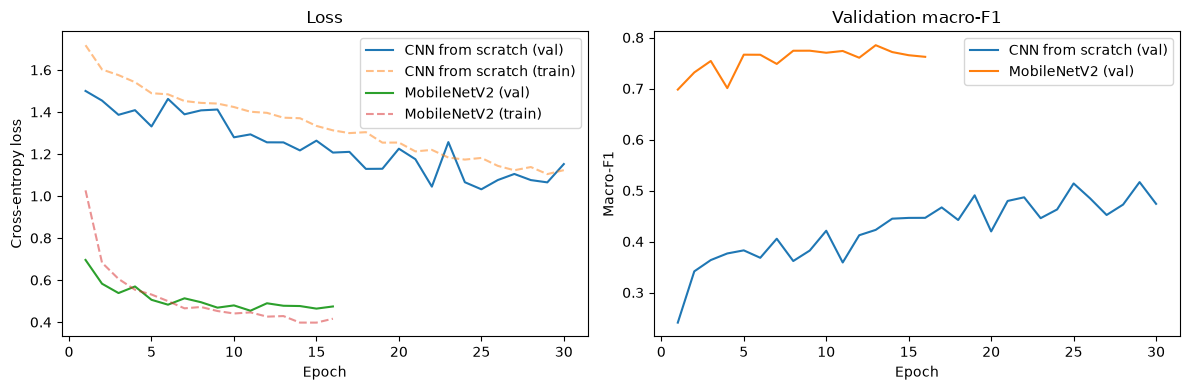

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, h in [("CNN from scratch", history_cnn), ("MobileNetV2", history_tl)]:
    ep = range(1, len(h["val_loss"]) + 1)
    axes[0].plot(ep, h["val_loss"], label=f"{name} (val)")
    axes[0].plot(ep, h["train_loss"], linestyle="--", alpha=0.5, label=f"{name} (train)")
    axes[1].plot(ep, h["val_f1"], label=f"{name} (val)")
axes[0].set(title="Loss", xlabel="Epoch", ylabel="Cross-entropy loss")
axes[1].set(title="Validation macro-F1", xlabel="Epoch", ylabel="Macro-F1")
axes[0].legend(); axes[1].legend()
plt.tight_layout(); plt.show()

### Classification report comparison

The 812 images are classified by `TransferNet` with an **accuracy of 0.84** and a **macro-F1 of 0.77**, against 0.335 and 0.084 for the majority-class baseline and 0.64 and 0.51 for `ArtistCNN`.

**Per-class results, compared with ArtistCNN**

| Painter | Precision | Recall | F1 | Support | F1 of ArtistCNN | Change in F1 |
|---|---:|---:|---:|---:|---:|---:|
| Van Gogh | 0.92 | 0.89 | 0.90 | 272 | 0.74 | +0.16 |
| Renoir | 0.95 | 0.81 | 0.88 | 198 | 0.64 | +0.24 |
| Monet | 0.80 | 0.88 | 0.84 | 191 | 0.70 | +0.14 |
| Cézanne | 0.80 | 0.77 | 0.79 | 83 | 0.31 | +0.48 |
| Morisot | 0.66 | 0.83 | 0.73 | 35 | 0.30 | +0.43 |
| Manet | 0.43 | 0.61 | 0.50 | 33 | 0.39 | +0.11 |

**Main observations**

**1. Every class improves, most of all those where ArtistCNN failed.** Cézanne’s F1 rose from 0.31 to 0.79 and Morisot’s from 0.30 to 0.73. The pretrained ImageNet features capture texture and structure better than the three convolutional blocks trained from scratch, which relied on coarse cues such as color and boldness of strokes. As a result, Cézanne’s constructive brushwork is no longer absorbed by Van Gogh, and Morisot’s soft, sketch-like handling is recognized far more often.

**2. The large classes are reliable.** Van Gogh (F1 0.90), Renoir (0.88), and Monet (0.84) all have precision and recall of at least 0.80. Renoir has the highest precision of the set (0.95): when the model says Renoir, it is almost always right. His recall (0.81) means that roughly 38 of his 198 paintings are assigned to other painters, probably his stylistic neighbors. Monet shows the opposite pattern, with recall (0.88) above precision (0.80), which suggests that some paintings by other painters are being labeled as Monet. This fits his role as the reference point of the style.

**3. Recall above precision for the small classes reflects the class weights.** For Morisot, a recall of 0.83 and a precision of 0.66 correspond to about 29 of 35 paintings found and roughly 15 false alarms. The weighted loss makes missing a rare painter costlier than a false alarm, so the model errs on the side of predicting them. The effect is the reason why the macro-averaged recall (0.80) exceeds the macro-averaged precision (0.76).

**4. Manet remains the weak point.** His F1 of 0.50 is the lowest, and his precision of 0.43 means that more than half of the paintings labeled Manet are by someone else. By the counts, about 20 of his 33 paintings are found, while the model predicts him around 47 times, so there are roughly 27 false alarms. This fits the diversity of his style, which ranges from flat, dark early work to loose outdoor scenes close to Impressionism, so he resembles several painters without a single stylistic signature. With only 33 images, each misclassified painting also shifts his recall by about 3 points, so his scores are the most uncertain in the report.

**5. The gap between the averages comes from the small classes.** Accuracy (0.84) and the weighted F1 (0.85) are well above the macro-F1 (0.77), because the three large classes, which make up 82% of the images, are recognized well, while Manet and Morisot pull the macro average down. This is the reason for using macro-F1 as the main metric.

**Conclusion and next steps**

TransferNet raises the accuracy from 0.64 to 0.84 and the macro-F1 from 0.51 to 0.77 compared with the scratch CNN, and it recognizes five of the six painters with an F1 of 0.73 or higher. The main remaining weakness is Manet, followed by the precision of Morisot. The most promising improvements is **fine-tuning** of the last backbone blocks at a low learning rate, so the high-level features adapt from photographs to painting style.

In [36]:
tl_loaded.eval()
y_true, y_pred = [], []
with torch.no_grad():
    for x, y in val_dl:
        y_pred += tl_loaded(x.to(device)).argmax(1).cpu().tolist()
        y_true += y.tolist()

print(classification_report(y_true, y_pred, target_names=classes))

              precision    recall  f1-score   support

    Cézanne       0.80      0.77      0.79        83
       Manet       0.43      0.61      0.50        33
       Monet       0.80      0.88      0.84       191
     Morisot       0.66      0.83      0.73        35
      Renoir       0.95      0.81      0.88       198
    Van Gogh       0.92      0.89      0.90       272

    accuracy                           0.84       812
   macro avg       0.76      0.80      0.77       812
weighted avg       0.86      0.84      0.85       812



In [40]:
rows = []
reports = {}
for name, net, best in [("CNN from scratch", cnn_loaded, best_epoch_cnn),
                        ("MobileNetV2 (frozen)", tl_loaded, best_epoch_tl)]:
    loss, y_true, y_pred = evaluate(net, val_dl, device, criterion)
    reports[name] = classification_report(y_true, y_pred, target_names=classes,
                                          output_dict=True, zero_division=0)
    rows.append({
        "model": name,
        # "train time": model_cnn["train_time"] if name == "CNN from scratch" else model_tl["train_time"],
        "best epoch": best,
        "val loss": round(loss, 3),
        "val accuracy": round(accuracy_score(y_true, y_pred), 3),
        "val macro-F1": round(f1_score(y_true, y_pred, average="macro"), 3),
        "trainable params": sum(p.numel() for p in net.parameters() if p.requires_grad),
    })

display(pd.DataFrame(rows).set_index('model'))

# per-class F1 side by side
per_class = pd.DataFrame({n: {c: r[c]["f1-score"] for c in classes} for n, r in reports.items()}).round(3)
display(per_class)

,best epoch,val loss,val accuracy,val macro-F1,trainable params
model,,,,,
CNN from scratch,25,1.032,0.643,0.514,94022
MobileNetV2 (frozen),11,0.454,0.842,0.774,7686


,CNN from scratch,MobileNetV2 (frozen)
Cézanne,0.306,0.785
Manet,0.386,0.500
Monet,0.705,0.843
Morisot,0.305,0.734
Renoir,0.639,0.875
Van Gogh,0.743,0.904


---
## 6. Fine-tuning the transfer-learning network

The first phase of transfer learning trained only the new classification head (7,686 weights) on top of a frozen MobileNetV2 backbone. This reached a macro-F1 of about 0.77, a large improvement over the scratch CNN, but the backbone’s features were learned from ImageNet photographs. Objects, scenes, and textures of photographs are not the same as the brushwork, color handling, and composition that distinguish painters. Fine-tuning addresses this by letting the deepest part of the backbone adapt to paintings, while the early layers, which detect generic edges and textures, stay unchanged. The training curves showed a plateau from about epoch 9 and a small, stable gap between training and validation, so the frozen model was limited by the capacity of its features and not by overfitting, which leaves room for fine-tuning to help.

**Training settings**

Updating that many weights on a few thousand paintings carries a risk of overfitting and of destroying the pretrained features (sometimes called catastrophic forgetting), so the fine-tuning phase is deliberately conservative:

- **A very low learning rate (1e-5)**, a hundred times lower than the 1e-3 used for the head, so each update only nudges the pretrained weights. The optimizer must be created again after unfreezing, with only the parameters that now require gradients.
- **The head is already trained.** Fine-tuning starts from the best frozen model (loaded from its checkpoint), because a randomly initialized head would send large, meaningless gradients into the pretrained blocks.
- **The same augmentation, class-weighted loss, and early stopping** (on the validation loss, restoring the best weights) as before, with a short maximum number of epochs, so the comparison with the frozen model is fair and training stops when the validation loss stops improving.
- **Only the last four blocks**, as a compromise: unfreezing more layers would add capacity and training time, with a greater risk of overfitting.

**Size of the change**

| Component | Trainable parameters (approximate) |
|---|---:|
| Frozen backbone, blocks 0 to 14 | 0 |
| Unfrozen convolution weights, blocks 15 to 18 | 1,510,720 |
| BatchNorm scale and shift in those blocks (kept frozen) | 0 |
| Classification head (`Linear 1280 → 6`) | 7,686 |
| **Total** | **about 1,518,000 (68% of 2,231,558)** |

Although only four of the 19 blocks are unfrozen, they hold about two thirds of the network’s weights, because the channel widths are largest at the end of the network. The number of trainable parameters therefore grows about 200 times compared with the head-only phase.

**How the effect is measured**

The fine-tuned model is compared with the frozen model on the same validation set, using validation loss, accuracy, macro-F1, and per-class F1, together with the extra training time. A bootstrap confidence interval for the difference in macro-F1 is useful here, because with Manet and Morisot at about 33 and 35 validation images, a small change could be noise. The frozen weights are saved beforehand, so the frozen model can be kept if fine-tuning does not help.

In [20]:
frozen_loss, y_true, y_pred_frozen = evaluate(tl_loaded, val_dl, device, criterion)
frozen = {
    "val loss": frozen_loss,
    "val accuracy": accuracy_score(y_true, y_pred_frozen),
    "val macro-F1": f1_score(y_true, y_pred_frozen, average="macro"),
}
print({k: round(v, 3) for k, v in frozen.items()})

frozen_state = deepcopy(tl_loaded.state_dict())

{'val loss': 0.45, 'val accuracy': 0.835, 'val macro-F1': 0.76}


In [21]:
N_UNFREEZE = 4     # last 4 of MobileNetV2's 19 feature blocks

for block in tl_loaded.base[-N_UNFREEZE:]:
    for p in block.parameters():
        p.requires_grad = True
    # keep BatchNorm scale/shift frozen (they also stay in eval mode, see below)
    for m in block.modules():
        if isinstance(m, nn.BatchNorm2d):
            for p in m.parameters():
                p.requires_grad = False

trainable = sum(p.numel() for p in tl_loaded.parameters() if p.requires_grad)
print(f"trainable params: {trainable:,}")

trainable params: 1,518,406


In [ ]:
opt_ft = torch.optim.AdamW(
    [p for p in tl_loaded.parameters() if p.requires_grad],
    lr=1e-5, weight_decay=1e-4,
)

start = time.perf_counter()
history_ft, best_epoch_ft = fit(tl_loaded, opt_ft, train_dl, val_dl, criterion, device, max_epochs=15, patience=5)
train_time_ft = time.perf_counter() - start
# fit restores the best weights of this fine-tuning phase
print(f"Training time: {train_time_ft/60:.1f} min")

In [23]:
torch.save({
    "model_state": tl_model.state_dict(),
    "best_epoch_ft": best_epoch_ft,
    "train_time": train_time_ft,
    "history_head": history_tl,
    "history_ft": history_ft,
    "classes": classes,
    "img_size": IMG_SIZE,
    "model_class": "TransferNet",
}, MODELS / "model_mobilenet_tuned.pt")

In [41]:
model_ft = torch.load(MODELS / "model_mobilenet_tuned.pt", map_location=device)
    
ft_loaded = TransferNet(num_classes=len(model_tl["classes"])).to(device)
ft_loaded.load_state_dict(model_ft["model_state"])
ft_loaded.eval()

TransferNet(
  (augment): Sequential(
    (0): RandomFlip()
    (1): RandomRotation()
    (2): RandomZoom()
  )
  (base): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU6(inplace=True)
    )
    (1): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
          (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
          (2): ReLU6(inplace=True)
        )
        (1): Conv2d(32, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      )
    )
    (2): InvertedResidual(
      (conv): Sequential(
        (0): Conv2d

### Evaluation of the fine-tuning curves

The plot joins the two training phases. The dotted vertical line (after epoch 16) marks the switch from the frozen backbone to fine-tuning of the last four blocks at a learning rate of 1e-5. 

| Quantity | Frozen phase (epochs 1–16) | Fine-tuning phase (epochs 17–31) |
|---|---|---|
| Best validation loss | about 0.455 (epoch 11) | about 0.385 (around epoch 27) |
| Validation loss, typical range | 0.46 to 0.49 | 0.39 to 0.44 |
| Validation macro-F1, typical range | 0.76 to 0.785 | 0.79 to 0.82, with one peak of about 0.84 (around epoch 27) |
| Training loss, end of phase | about 0.40 to 0.42 | about 0.16 |
| Training macro-F1, end of phase | about 0.82 | about 0.94 |
| Gap train vs. validation, loss | about 0.06 | about 0.24 |
| Gap train vs. validation, macro-F1 | about 0.06 | about 0.14 |

**1. Fine-tuning improves the validation scores, modestly**

The validation loss drops from a best of about 0.455 to a range of 0.39 to 0.43, and the validation macro-F1 rises from the 0.76 to 0.785 range to roughly 0.80 to 0.82. The very first fine-tuning epoch already sits below the frozen model’s loss, which shows that adapting the top blocks gives a quick gain. The improvement is real but small compared with the jump from the scratch CNN (macro-F1 about 0.51) to the frozen model (about 0.77): fine-tuning adds roughly 0.03 to 0.05 of macro-F1 on a typical epoch. This matches the expectation that most of the benefit of the pretrained features is already captured by the frozen head.

**2. The model now fits the training data much better than unseen data**

The training loss keeps falling in a nearly straight line, from about 0.39 to 0.16, and the training F1 climbs from 0.83 to 0.94, while the validation curves flatten from about epoch 21. The gap between the two grows from about 0.06 to 0.24 in loss and from 0.06 to 0.14 in F1. In the frozen phase the gap was small and stable, so the difference comes from the 1.5 million newly trainable weights, which give the network enough capacity to start memorizing the training images. The training metrics are computed with augmentation and dropout active, so the real gap is, if anything, larger than the plot shows.

**3. A plateau, not a deterioration**

The validation loss does not rise in the long run: it oscillates between about 0.385 and 0.435 for the last ten epochs. The pattern is therefore a plateau combined with a widening generalization gap (mild overfitting), not a collapse of the validation performance. That is why continued training only increases the training score without helping the validation score. More epochs would not help, and the useful training in this phase ended around epoch 21 to 27.

**4. Noisy validation curves and a possibly optimistic peak**

The validation F1 moves by 0.01 to 0.03 from one epoch to the next, and the validation loss shows similar jumps (for example the rise at epoch 18 and the dips around epochs 25 and 27). The Manet and Morisot classes have only about 33 and 35 validation images, so a few changed predictions move the macro-F1 visibly. The peak of about 0.84 around epoch 27 stands well above its neighbors (about 0.81 and 0.82), and early stopping selects the epoch with the lowest validation loss, which coincides with it. Choosing the best of many noisy epochs biases the selected score upward, so the realistic improvement is better represented by the plateau level (about 0.80 to 0.82) than by the peak.

**5. Early stopping and the length of the phase**

The fine-tuning curves run for 15 epochs (17 to 31), which matches the maximum of max_epochs=15, so the phase apparently ended because of the epoch limit and not because of early stopping. Either way, the restored weights are those of the epoch with the lowest validation loss in this phase, and the comparison with the frozen model must still use the saved frozen baseline.

**Conclusion**

Fine-tuning gives a modest but consistent improvement in validation loss and macro-F1 over the frozen model, with a clear price: the training score climbs far above the validation score, which shows that the model starts to overfit once the top blocks are free. 

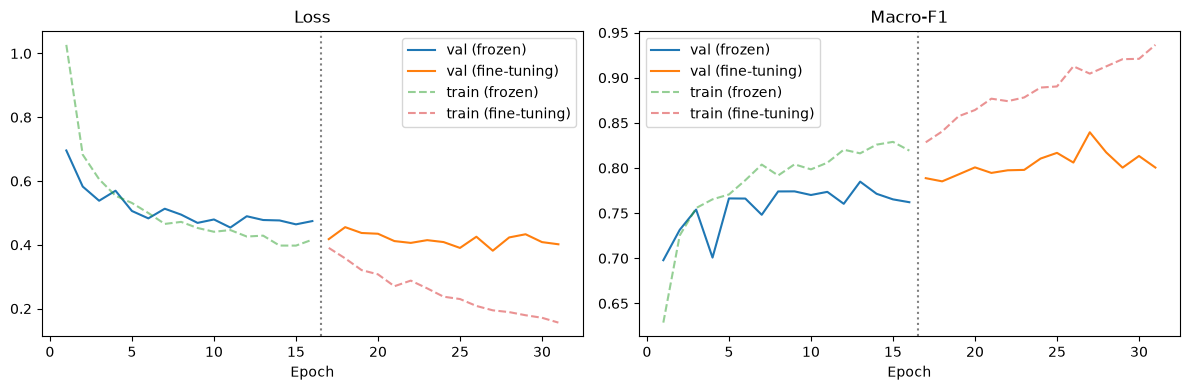

In [43]:
n_head = len(history_tl["val_loss"])
ep_head = range(1, n_head + 1)
ep_ft = range(n_head + 1, n_head + len(history_ft["val_loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, key, title in [(axes[0], "loss", "Loss"), (axes[1], "f1", "Macro-F1")]:
    ax.plot(ep_head, history_tl[f"val_{key}"], label="val (frozen)")
    ax.plot(ep_ft, history_ft[f"val_{key}"], label="val (fine-tuning)")
    ax.plot(ep_head, history_tl[f"train_{key}"], "--", alpha=0.5, label="train (frozen)")
    ax.plot(ep_ft, history_ft[f"train_{key}"], "--", alpha=0.5, label="train (fine-tuning)")
    ax.axvline(n_head + 0.5, color="gray", linestyle=":")
    ax.set(title=title, xlabel="Epoch")
    ax.legend()
plt.tight_layout(); plt.show()

### Comparison of the frozen vs. fine-tuned models:

Both models were scored on the same validation set, with the same preprocessing and class-weighted loss. The fine-tuned model is better on every metric, and the improvement is consistent across all six painters.

**Overall metrics**

| Model | Val loss | Val accuracy | Val macro-F1 |
|---|---:|---:|---:|
| Frozen | 0.450 | 0.835 | 0.76 |
| Fine-tuned | 0.403 | 0.878 | 0.82 |
| **Change** | **-0.047 (about -10%)** | **+0.043** | **+0.06** |

- **Loss**: the validation loss falls by about 10%, so the model assigns higher probability to the correct painter. 
- **Accuracy**: the error rate drops from 16.5% to 12.2%, about a quarter fewer mistakes. In the 812-image validation set, that is roughly 35 more images classified correctly.
- **Macro-F1**: the gain of 0.06 is larger than the gain in accuracy (0.043), which means the improvement is concentrated in the smaller classes, as the per-class table shows below.

**Per-class F1**

| Painter | Frozen | Fine-tuned | Change |
|---|---:|---:|---:|
| Van Gogh | 0.890 | 0.925 | +0.035 |
| Renoir | 0.875 | 0.911 | +0.036 |
| Monet | 0.843 | 0.888 | +0.045 |
| Morisot | 0.737 | 0.827 | +0.090 |
| Cézanne | 0.782 | 0.821 | +0.039 |
| Manet | 0.432 | 0.548 | +0.116 |

**Main observations**

1. **The gain is broad.** No class got worse, and the large classes (Van Gogh, Renoir, Monet) improved by 0.035 to 0.045. A gain that appears in all six classes is stronger evidence of a real effect than a gain in one class would be, since each class is a partly independent test.

2. **The gains are largest where the model was weakest.** Manet improved the most (+0.116) and Morisot next (+0.090), compared with about +0.04 for the other four. The large classes were already recognized well, so they had less room to improve, and that is why the macro-F1 gain (+0.06) exceeds the accuracy gain (+0.043).

3. **Manet remains the weak point.** Even after the largest gain, his F1 of 0.548 is far below the other painters (0.82 to 0.93). His style ranges from flat, dark early work to loose outdoor scenes, so he resembles several painters without a single signature, and fine-tuning has only partly resolved this.

In [46]:
# ft_loss, y_true, y_pred_ft = evaluate(tl_model, val_dl, device, criterion)
ft_loss, y_true, y_pred_ft = evaluate(ft_loaded, val_dl, device, criterion)

history_ft = model_ft["history_ft"]
best_epoch_ft = model_ft["best_epoch_ft"]

fine = {
    "val loss": ft_loss,
    "val accuracy": accuracy_score(y_true, y_pred_ft),
    "val macro-F1": f1_score(y_true, y_pred_ft, average="macro"),
}

comparison = pd.DataFrame({"frozen": frozen, "fine-tuned": fine}).T.round(3)
# comparison["extra time (min)"] = [0, round(history_ft["total_time"] / 60, 1)]
display(comparison)

# per-class F1
rep_fz = classification_report(y_true, y_pred_frozen, target_names=classes, output_dict=True, zero_division=0)
rep_ft = classification_report(y_true, y_pred_ft, target_names=classes, output_dict=True, zero_division=0)
per_class = pd.DataFrame({
    "frozen": {c: rep_fz[c]["f1-score"] for c in classes},
    "fine-tuned": {c: rep_ft[c]["f1-score"] for c in classes},
}).round(3)
per_class["change"] = (per_class["fine-tuned"] - per_class["frozen"]).round(3)
display(per_class)

,val loss,val accuracy,val macro-F1
frozen,0.450,0.835,0.76
fine-tuned,0.403,0.878,0.82


,frozen,fine-tuned,change
Cézanne,0.782,0.821,0.039
Manet,0.432,0.548,0.116
Monet,0.843,0.888,0.045
Morisot,0.737,0.827,0.090
Renoir,0.875,0.911,0.036
Van Gogh,0.890,0.925,0.035


---
## 7. The final model

Which model, which parameters, which threshold, and why.

Fine-tuning the last four blocks of MobileNetV2 at a low learning rate improved the validation macro-F1 from 0.76 to 0.82, the accuracy from 0.835 to 0.878, and the loss from 0.450 to 0.403, with gains in every class and the largest ones for Manet and Morisot. **The fine-tuned model is therefore the better candidate and should be kept**. Its remaining weaknesses are Manet (F1 about 0.55) and a visible gap between training and validation scores, which could be reduced by stronger regularization, a probability or class-weight adjustment for the small classes, or higher-resolution inputs. Since the validation set was used for early stopping and for this comparison, the final performance claim should be based on a single evaluation of the chosen model on the test set.